# Task 05: Deep Learning / NLP Text Classifier with PyTorch

**Project:** Sentiment Analysis (Positive vs Negative)  
**Student:** Tharani P  
**Department:** Artificial Intelligence and Data Science

## Objective
Build a reproducible NLP classification pipeline with TF-IDF, a multi-layer PyTorch neural network, training/validation curves, evaluation metrics, and confidence-scored predictions.

**Dataset transparency:** To keep this notebook self-contained, it creates a balanced, template-based demonstration dataset. This is useful for testing the complete workflow, but it is not a real-world review dataset and its scores must not be presented as real-world performance. For a stronger final submission, replace it with a larger real labeled review dataset.


## 1. Import libraries

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


Device: cpu


## 2. Prepare labeled text data

In [2]:
# A balanced, reproducible demo corpus generated from varied sentiment templates.
# This avoids external downloads, but it is still a synthetic teaching dataset, not a benchmark.
import itertools

positive_words = ["excellent", "wonderful", "helpful", "reliable", "enjoyable", "impressive", "pleasant", "fantastic"]
negative_words = ["terrible", "awful", "useless", "unreliable", "frustrating", "disappointing", "unpleasant", "poor"]
items = ["movie", "product", "application", "service", "purchase", "experience", "design", "delivery", "lesson", "performance"]
positive_templates = [
    "I found the {item} {word}.",
    "Overall, the {item} was {word}.",
    "My experience with this {item} was {word}.",
    "The {item} turned out to be {word}.",
    "I am happy because the {item} is {word}.",
    "People will find this {item} {word}.",
    "I would describe the {item} as {word}.",
    "The quality of the {item} is {word}.",
]
negative_templates = [
    "I found the {item} {word}.",
    "Overall, the {item} was {word}.",
    "My experience with this {item} was {word}.",
    "The {item} turned out to be {word}.",
    "I am unhappy because the {item} is {word}.",
    "People will find this {item} {word}.",
    "I would describe the {item} as {word}.",
    "The quality of the {item} is {word}.",
]
positive_texts = [t.format(item=item, word=word) for item, word, t in itertools.product(items, positive_words, positive_templates)]
negative_texts = [t.format(item=item, word=word) for item, word, t in itertools.product(items, negative_words, negative_templates)]

texts = positive_texts + negative_texts
labels = [1] * len(positive_texts) + [0] * len(negative_texts)
df = pd.DataFrame({"text": texts, "label": labels})
df["sentiment"] = df["label"].map({1: "positive", 0: "negative"})
df = df.sample(frac=1, random_state=SEED).reset_index(drop=True)

print("Dataset shape:", df.shape)
display(df.sample(5, random_state=SEED))
print("\\nClass counts:")
print(df["sentiment"].value_counts())
print("\\nDataset note: generated template-based examples for reproducible demonstration; replace with real labeled reviews for a real-world evaluation.")


Dataset shape: (1280, 3)


,text,label,sentiment
1240,I am happy because the movie is helpful.,1,positive
695,My experience with this experience was helpful.,1,positive
899,The performance turned out to be reliable.,1,positive
770,I am unhappy because the purchase is useless.,0,negative
743,People will find this product awful.,0,negative


\nClass counts:
sentiment
negative    640
positive    640
Name: count, dtype: int64
\nDataset note: generated template-based examples for reproducible demonstration; replace with real labeled reviews for a real-world evaluation.


## 3. Split the data and convert text to TF-IDF vectors

In [3]:
X_train_text, X_test_text, y_train, y_test = train_test_split(
    df["text"], df["label"].values,
    test_size=0.25, random_state=SEED, stratify=df["label"].values
)

# Split a validation set from the training data.
X_train_text, X_val_text, y_train, y_val = train_test_split(
    X_train_text, y_train,
    test_size=0.20, random_state=SEED, stratify=y_train
)

vectorizer = TfidfVectorizer(max_features=3000, ngram_range=(1, 2), lowercase=True)
X_train = vectorizer.fit_transform(X_train_text).toarray().astype(np.float32)
X_val = vectorizer.transform(X_val_text).toarray().astype(np.float32)
X_test = vectorizer.transform(X_test_text).toarray().astype(np.float32)

y_train = np.asarray(y_train, dtype=np.int64)
y_val = np.asarray(y_val, dtype=np.int64)
y_test = np.asarray(y_test, dtype=np.int64)

print("Train:", X_train.shape, "Validation:", X_val.shape, "Test:", X_test.shape)


Train: (768, 327) Validation: (192, 327) Test: (320, 327)


## 4. Create PyTorch datasets and data loaders

In [4]:
def make_loader(features, targets, batch_size=8, shuffle=False):
    x_tensor = torch.tensor(features, dtype=torch.float32)
    y_tensor = torch.tensor(targets, dtype=torch.long)
    return DataLoader(TensorDataset(x_tensor, y_tensor), batch_size=batch_size, shuffle=shuffle)

train_loader = make_loader(X_train, y_train, shuffle=True)
val_loader = make_loader(X_val, y_val)
test_loader = make_loader(X_test, y_test)


## 5. Build a multi-layer neural network

In [5]:
class SentimentMLP(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.20),
            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.15),
            nn.Linear(64, 2)
        )

    def forward(self, x):
        return self.network(x)

model = SentimentMLP(X_train.shape[1]).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)
print(model)


SentimentMLP(
  (network): Sequential(
    (0): Linear(in_features=327, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.15, inplace=False)
    (8): Linear(in_features=64, out_features=2, bias=True)
  )
)


## 6. Train with validation and early stopping

In [6]:
def run_epoch(loader, training):
    model.train(training)
    total_loss, total_correct, total_count = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        if training:
            optimizer.zero_grad()
        with torch.set_grad_enabled(training):
            logits = model(xb)
            loss = criterion(logits, yb)
            if training:
                loss.backward()
                optimizer.step()
        total_loss += loss.item() * len(yb)
        total_correct += (logits.argmax(dim=1) == yb).sum().item()
        total_count += len(yb)
    return total_loss / total_count, total_correct / total_count

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_val_loss = float("inf")
best_state = None
patience = 10
epochs_without_improvement = 0
max_epochs = 60

for epoch in range(max_epochs):
    train_loss, train_acc = run_epoch(train_loader, training=True)
    val_loss, val_acc = run_epoch(val_loader, training=False)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(f"Epoch {epoch+1:03d} | train loss {train_loss:.4f} | val loss {val_loss:.4f} | train acc {train_acc:.3f} | val acc {val_acc:.3f}")

    if epochs_without_improvement >= patience:
        print(f"Early stopping at epoch {epoch+1}")
        break

if best_state is not None:
    model.load_state_dict(best_state)


Epoch 001 | train loss 0.4413 | val loss 0.1427 | train acc 0.790 | val acc 0.995


Epoch 010 | train loss 0.0330 | val loss 0.0033 | train acc 0.992 | val acc 1.000


Epoch 020 | train loss 0.0244 | val loss 0.0012 | train acc 0.995 | val acc 1.000


Epoch 030 | train loss 0.0359 | val loss 0.0009 | train acc 0.993 | val acc 1.000


Early stopping at epoch 33


## 7. Plot loss and accuracy convergence curves

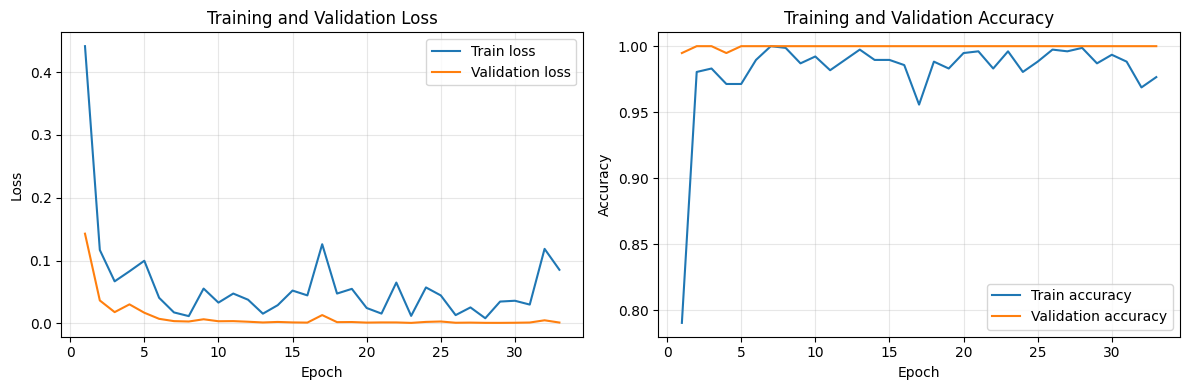

In [7]:
epochs_ran = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(epochs_ran, history["train_loss"], label="Train loss")
plt.plot(epochs_ran, history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(epochs_ran, history["train_acc"], label="Train accuracy")
plt.plot(epochs_ran, history["val_acc"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 8. Evaluate on unseen test data

Test accuracy: 1.000

Classification report:
              precision    recall  f1-score   support

    negative       1.00      1.00      1.00       160
    positive       1.00      1.00      1.00       160

    accuracy                           1.00       320
   macro avg       1.00      1.00      1.00       320
weighted avg       1.00      1.00      1.00       320



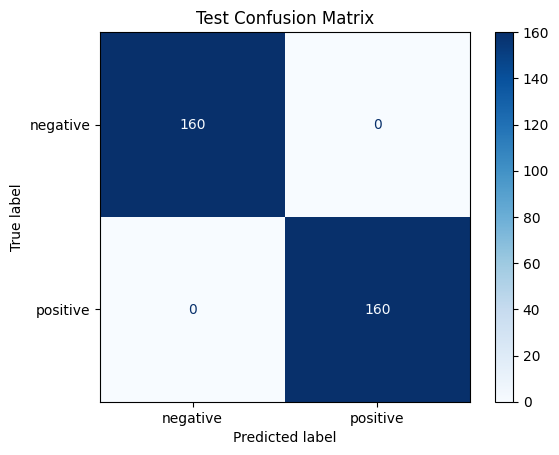

In [8]:
model.eval()
with torch.no_grad():
    test_logits = model(torch.tensor(X_test, dtype=torch.float32).to(device))
    test_probs = torch.softmax(test_logits, dim=1).cpu().numpy()
    test_predictions = test_probs.argmax(axis=1)

print(f"Test accuracy: {accuracy_score(y_test, test_predictions):.3f}")
print("\nClassification report:")
print(classification_report(y_test, test_predictions, target_names=["negative", "positive"], zero_division=0))

cm = confusion_matrix(y_test, test_predictions, labels=[0, 1])
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["negative", "positive"]).plot(cmap="Blues")
plt.title("Test Confusion Matrix")
plt.show()


## 9. Predict sentiment for new sample inputs with confidence

In [9]:
def predict_sentiment(text):
    vector = vectorizer.transform([text]).toarray().astype(np.float32)
    model.eval()
    with torch.no_grad():
        logits = model(torch.tensor(vector, dtype=torch.float32).to(device))
        probabilities = torch.softmax(logits, dim=1).cpu().numpy()[0]
    predicted_index = int(np.argmax(probabilities))
    sentiment = "positive" if predicted_index == 1 else "negative"
    confidence = float(probabilities[predicted_index])
    return {"text": text, "predicted_sentiment": sentiment, "confidence": round(confidence, 4),
            "negative_probability": round(float(probabilities[0]), 4),
            "positive_probability": round(float(probabilities[1]), 4)}

samples = [
    "I really love this product, it is excellent",
    "This was a terrible experience and I am disappointed",
    "The service was helpful and the delivery was fast",
    "The app is confusing and it does not work well"
]

results = pd.DataFrame([predict_sentiment(s) for s in samples])
display(results)


,text,predicted_sentiment,confidence,negative_probability,positive_probability
0,"I really love this product, it is excellent",positive,1.0000,0.0000,1.0000
1,This was a terrible experience and I am disapp...,negative,1.0000,1.0000,0.0000
2,The service was helpful and the delivery was fast,positive,0.9997,0.0003,0.9997
3,The app is confusing and it does not work well,positive,0.6470,0.3530,0.6470


## 10. Save the trained model and vectorizer

In [10]:
# Save model weights and vocabulary for reproducibility.
torch.save(model.state_dict(), "sentiment_model.pth")
import pickle
with open("tfidf_vectorizer.pkl", "wb") as f:
    pickle.dump(vectorizer, f)

print("Saved sentiment_model.pth and tfidf_vectorizer.pkl")


Saved sentiment_model.pth and tfidf_vectorizer.pkl


## Conclusion
This project demonstrates text vectorization with TF-IDF, a multi-layer PyTorch neural network with Batch Normalization and Dropout, validation-based early stopping, training/validation loss and accuracy curves, a confusion matrix, and confidence-scored predictions for new text.

The included data is synthetic and template-based, for reproducible pipeline demonstration only. For a realistic evaluation, replace it with a real labeled sentiment dataset, rerun the notebook, and report the resulting metrics honestly.
